<a href="https://colab.research.google.com/github/andrelison/salesinsight-py/blob/feat%2Fpipeline-dados/salesinsigtht.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Etapa 1: dados e inspeção (RF01 e RF02)

In [4]:
import json
import os
import random
import re
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter


In [5]:
# RF01 - CRIAR OU CARREGAR O DATASET


def gerar_dataset_vendas(n_registros=200, seed=42):
    """Gera um dataset sintetico de vendas com dados sujos."""
    random.seed(seed)
    np.random.seed(seed)

    produtos = ["Notebook", "Smartphone", "Tablet", "Monitor",
                "Teclado", "Mouse", "Headset"]
    categorias = {"Notebook": "Computadores", "Smartphone": "Celulares",
                  "Tablet": "Celulares", "Monitor": "Computadores",
                  "Teclado": "Perifericos", "Mouse": "Perifericos",
                  "Headset": "Perifericos"}
    precos = {"Notebook": 3500, "Smartphone": 2200, "Tablet": 1800,
              "Monitor": 1200, "Teclado": 250, "Mouse": 120,
              "Headset": 350}
    regioes = ["Sudeste", "Sul", "Nordeste", "Centro-Oeste", "Norte"]

    data_inicio = datetime(2025, 1, 1)
    dados = []

    for i in range(n_registros):
        produto = random.choice(produtos)
        categoria = categorias[produto]
        quantidade = random.randint(1, 10)
        preco = round(precos[produto] * random.uniform(0.85, 1.15), 2)
        data = data_inicio + timedelta(days=random.randint(0, 364))
        data_txt = data.strftime("%Y-%m-%d")
        cliente = f"Cliente_{random.randint(1, 50):03d}"

        # --- sujeira proposital para a etapa de limpeza ---
        if random.random() < 0.03:
            data_txt = "DATA INVALIDA"

        dados.append({
            "id_venda": i + 1,
            "data_venda": data_txt,
            "cliente": cliente,
            "produto": produto,
            "categoria": categoria,
            "regiao": random.choice(regioes),
            "quantidade": quantidade,
            "preco_unitario": preco,
        })

    return pd.DataFrame(dados)


In [6]:
# RF02 - INSPECIONAR E DESCREVER OS DADOS

def inspecionar_dados(df):
    """Exibe as informacoes estruturais do DataFrame."""
    print("\n=== INSPECAO INICIAL DO DATASET ===")
    print(f"Shape: {df.shape}")
    print(f"\nColunas: {list(df.columns)}")
    print(f"\nTipos de dados:\n{df.dtypes}")
    print(f"\nValores nulos por coluna:\n{df.isnull().sum()}")
    print(f"\nPrimeiros registros:\n{df.head()}")
    return df

In [7]:
# =============================================================================
# RF03 - TRATAR OS DADOS (DATETIME)
# =============================================================================

def tratar_dados(df):
    """
    Trata o DataFrame de vendas (RF03).
    Retorna: (df_limpo, relatorio), onde relatorio e um dicionario
    com as contagens de registros iniciais, convertidos e finais.
    """
    df = df.copy()
    antes = df.copy()                      # copia para comparar depois
    registros_iniciais = len(df)

    # 1. remover espacos extras nas colunas de texto
    colunas_texto = df.select_dtypes(include=["object", "string"]).columns
    for col in colunas_texto:
        df[col] = df[col].str.strip()
    # True nas linhas em que algum texto mudou depois do strip
    mudou_texto = (
        antes[colunas_texto].fillna("") != df[colunas_texto].fillna("")
    ).any(axis=1)

        # verificacao informativa com regex: nomes de cliente fora do padrao
    # (apenas conta e informa, nenhum registro e alterado ou removido)
    clientes_fora_do_padrao = int(
        (~df["cliente"].apply(lambda c: bool(re.match(r"^Cliente_\d{3}$", str(c))))).sum()
    )

    # 2. converter data_venda e descartar datas invalidas
    df["data_venda"] = pd.to_datetime(df["data_venda"], errors="coerce")
    datas_invalidas = int(df["data_venda"].isna().sum())
    df = df[df["data_venda"].notna()].copy()
    datas_convertidas = len(df)

    # 3. ajustar tipos numericos
    tipos_ajustados = 0
    for coluna, tipo in {"quantidade": int, "preco_unitario": float}.items():
        convertida = df[coluna].astype(tipo)
        if convertida.dtype != antes[coluna].dtype:
            tipos_ajustados += 1
        df[coluna] = convertida

# 4. montar e imprimir o relatorio de limpeza
    # "sem alteracao" = linhas cujo texto e tipos numericos nao mudaram
    if tipos_ajustados == 0:
        sem_alteracao = int((~mudou_texto.loc[df.index]).sum())
    else:
        sem_alteracao = 0

    relatorio = {
        "registros_iniciais": registros_iniciais,
        "espacos_removidos (linhas)": int(mudou_texto.sum()),
        "datas_convertidas (texto -> datetime)": datas_convertidas,
        "datas_invalidas_removidas": datas_invalidas,
        "colunas_numericas_ajustadas": tipos_ajustados,
        "clientes_fora_do_padrao (informativo)": clientes_fora_do_padrao,
        "registros_sem_alteracao": sem_alteracao,
        "registros_finais": len(df),
    }


    print("\n=== RELATORIO DE LIMPEZA ===")
    for chave, valor in relatorio.items():
        print(f"  {chave}: {valor}")

    return df.reset_index(drop=True), relatorio




In [8]:
# =============================================================================
# RF04 - COLUNAS DERIVADAS COM TRANSFORMACOES CONDICIONAIS
# =============================================================================

def criar_colunas_derivadas(df):
    """Cria as colunas derivadas exigidas no RF04."""
    df = df.copy()

    df["receita_total"] = df["quantidade"] * df["preco_unitario"]
    df["mes"] = df["data_venda"].dt.month
    df["mes_nome"] = df["mes"].map(MESES_PT)
    df["trimestre"] = "Q" + df["data_venda"].dt.quarter.astype(str)
    df["ano"] = df["data_venda"].dt.year

    condicoes = [
        df["receita_total"] < 500,
        (df["receita_total"] >= 500) & (df["receita_total"] < 5000),
        df["receita_total"] >= 5000,
    ]
    faixas = ["Baixo Valor", "Medio Valor", "Alto Valor"]
    df["faixa_receita_item"] = np.select(condicoes, faixas, default="Nao Classificado")

    return df


In [9]:
# =============================================================================
# RF05 - METRICAS AGREGADAS COM GROUPBY
# =============================================================================

def calcular_metricas(df):
    """
    Calcula as metricas agregadas do dataset (RF05).
    Retorna um dicionario no formato {nome_da_metrica: DataFrame}.
    Chaves: por_mes, top_produtos, por_categoria, por_regiao.
    """
    metricas = {}

    # receita, quantidade e numero de vendas por mes
    metricas["por_mes"] = (
        df.groupby("mes")
        .agg(
            receita_total=("receita_total", "sum"),
            quantidade=("quantidade", "sum"),
            n_vendas=("id_venda", "count"),
        )
        .reset_index()
        .sort_values("mes")
    )

    # Top 5 produtos por receita, em ordem decrescente
    metricas["top_produtos"] = (
        df.groupby("produto")["receita_total"].sum()
        .reset_index()
        .sort_values("receita_total", ascending=False)
        .head(5)
    )

    # receita total por categoria
    metricas["por_categoria"] = (
        df.groupby("categoria")["receita_total"].sum()
        .reset_index()
        .sort_values("receita_total", ascending=False)
    )

    # receita total e ticket medio por regiao
    metricas["por_regiao"] = (
        df.groupby("regiao")
        .agg(
            receita_total=("receita_total", "sum"),
            ticket_medio=("receita_total", "mean"),
        )
        .reset_index()
        .sort_values("receita_total", ascending=False)
    )

    return metricas


def exibir_metricas(metricas):
    """Imprime cada metrica com um titulo legivel."""
    titulos = {
        "por_mes": "POR MES",
        "top_produtos": "TOP 5 PRODUTOS",
        "por_categoria": "POR CATEGORIA",
        "por_regiao": "POR REGIAO",
    }
    for chave, tabela in metricas.items():
        print(f"\n=== {titulos.get(chave, chave.upper())} ===")
        print(tabela.round(2).to_string(index=False))

In [10]:
# =============================================================================
# RF06 - SEGMENTAR CLIENTES POR NIVEL DE GASTO
# =============================================================================

def segmentar_clientes(df):
    """
    Agrupa por cliente, soma a receita e classifica em Bronze / Prata / Ouro (RF06).
    Retorna um DataFrame com: cliente, total_gasto, segmento.
    """
    clientes = (
        df.groupby("cliente")["receita_total"].sum()
        .reset_index()
        .rename(columns={"receita_total": "total_gasto"})
    )

    clientes["segmento"] = clientes["total_gasto"].apply(
        lambda gasto: "Bronze" if gasto < 5000
        else ("Prata" if gasto <= 15000 else "Ouro")
    )

    return clientes.sort_values("total_gasto", ascending=False).reset_index(drop=True)


def exibir_segmentacao(clientes):
    """Mostra os 10 maiores clientes e a distribuicao por segmento."""
    print("\n=== TOP 10 CLIENTES ===")
    print(clientes.head(10).round(2).to_string(index=False))
    print("\n=== DISTRIBUICAO POR SEGMENTO ===")
    print(clientes["segmento"].value_counts())


In [11]:
# =============================================================================
# RF07 - VISUALIZACOES COM MATPLOTLIB E SEABORN
# =============================================================================

def configurar_estilo():
    """Define o estilo visual global dos graficos."""
    sns.set_theme(style="whitegrid")
    plt.rcParams["figure.figsize"] = (12, 6)
    plt.rcParams["axes.titlesize"] = 14


def formatar_reais(ax, eixo="y"):
    """Formata os valores de um eixo como 'R$ 100 mil'."""
    eixo_alvo = ax.yaxis if eixo == "y" else ax.xaxis
    eixo_alvo.set_major_formatter(
        FuncFormatter(lambda v, _: f"R$ {v / 1000:.0f} mil")
    )


def desenhar_linha_mes(ax, por_mes):
    """Linha: receita total por mes."""
    ax.plot(por_mes["mes"], por_mes["receita_total"], marker="o",
            linewidth=2, color=COR_PRINCIPAL, label="Receita total")
    ax.set_title("Receita Total por Mes")
    ax.set_xlabel("Mes")
    ax.set_ylabel("Receita total (R$)")
    ax.set_xticks(por_mes["mes"])
    ax.set_xticklabels([MESES_PT[m][:3] for m in por_mes["mes"]])
    formatar_reais(ax)
    ax.legend(loc="upper right")


def desenhar_barras_produtos(ax, top_produtos):
    """Barras: Top 5 produtos por receita."""
    sns.barplot(data=top_produtos, y="produto", x="receita_total",
                hue="produto", palette="Blues_d", legend=False, ax=ax)
    ax.set_title("Top 5 Produtos por Receita")
    ax.set_xlabel("Receita total (R$)")
    ax.set_ylabel("Produto")
    formatar_reais(ax, eixo="x")


def desenhar_dispersao(ax, df):
    """Dispersao: quantidade x receita, colorido por categoria."""
    sns.scatterplot(data=df, x="quantidade", y="receita_total", hue="categoria",
                    palette=PALETA_CATEGORIAS, alpha=0.7, s=60, ax=ax)
    ax.set_title("Quantidade x Receita por Transacao")
    ax.set_xlabel("Quantidade vendida")
    ax.set_ylabel("Receita da transacao (R$)")
    ax.legend(title="Categoria")


def desenhar_receita_regiao(ax, por_regiao):
    """Barras: receita total por regiao."""
    ax.bar(por_regiao["regiao"], por_regiao["receita_total"],
           color="#5D6D7E", label="Receita total")
    ax.set_title("Receita Total por Regiao")
    ax.set_xlabel("Regiao")
    ax.set_ylabel("Receita total (R$)")
    ax.tick_params(axis="x", rotation=20)
    formatar_reais(ax)


def salvar_figura(fig, nome, pasta, dpi=150):
    """Ajusta o layout, salva a figura em PNG e a fecha."""
    caminho = os.path.join(pasta, nome)
    fig.tight_layout()
    fig.savefig(caminho, dpi=dpi)
    plt.close(fig)
    return caminho


def gerar_graficos(df, metricas, pasta="outputs/graficos"):
    """Gera as 4 figuras do RF07 e retorna a lista de caminhos salvos."""
    configurar_estilo()
    os.makedirs(pasta, exist_ok=True)
    caminhos = []

    # 1. linha: receita por mes
    fig, ax = plt.subplots(figsize=(10, 5))
    desenhar_linha_mes(ax, metricas["por_mes"])
    caminhos.append(salvar_figura(fig, "receita_por_mes.png", pasta))

    # 2. barras: top 5 produtos
    fig, ax = plt.subplots(figsize=(10, 5))
    desenhar_barras_produtos(ax, metricas["top_produtos"])
    caminhos.append(salvar_figura(fig, "top_produtos.png", pasta))

    # 3. dispersao: quantidade x receita
    fig, ax = plt.subplots(figsize=(10, 6))
    desenhar_dispersao(ax, df)
    caminhos.append(salvar_figura(fig, "quantidade_vs_receita.png", pasta))

    # 4. painel 2x2 com subplots
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    desenhar_linha_mes(axes[0, 0], metricas["por_mes"])
    desenhar_barras_produtos(axes[0, 1], metricas["top_produtos"])
    desenhar_dispersao(axes[1, 0], df)
    desenhar_receita_regiao(axes[1, 1], metricas["por_regiao"])
    fig.suptitle("SalesInsight PY - Painel Resumo", fontsize=16)
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    caminho_painel = os.path.join(pasta, "painel_resumo.png")
    fig.savefig(caminho_painel, dpi=150)
    plt.close(fig)
    caminhos.append(caminho_painel)

    print("\n=== GRAFICOS SALVOS ===")
    for caminho in caminhos:
        print(f"  {caminho}")

    return caminhos


In [12]:
# =============================================================================
# RF08 - FUNCOES REUTILIZAVEIS E FUNCAO DE ORDEM SUPERIOR
# =============================================================================

def processar_coluna(df, coluna, funcao_transformacao, nome_saida=None):
    """
    Aplica uma funcao de transformacao a uma coluna do DataFrame (RF08).
    Demonstra o uso de funcoes como argumento (funcao de ordem superior).
    """
    nome_saida = nome_saida or f"{coluna}_transformado"
    df[nome_saida] = df[coluna].apply(funcao_transformacao)
    return df

In [13]:
# =============================================================================
# RF09 - EXPORTAR RESULTADOS EM CSV E JSON
# =============================================================================

def calcular_estatisticas_gerais(df, clientes):
    """Resume o dataset em um dicionario de estatisticas gerais."""
    return {
        "total_vendas": int(len(df)),
        "receita_total": float(df["receita_total"].sum()),
        "ticket_medio": float(df["receita_total"].mean()),
        "quantidade_total": int(df["quantidade"].sum()),
        "total_clientes": int(len(clientes)),
        "clientes_ouro": int((clientes["segmento"] == "Ouro").sum()),
    }


def exportar_resultados(metricas, clientes, estatisticas, pasta="outputs"):
    """Exporta os resultados em CSV e JSON e le o JSON de volta (RF09)."""
    os.makedirs(pasta, exist_ok=True)

    metricas["por_mes"].to_csv(
        os.path.join(pasta, "metricas_por_mes.csv"),
        index=False, encoding="utf-8-sig")
    clientes.to_csv(
        os.path.join(pasta, "segmentacao_clientes.csv"),
        index=False, encoding="utf-8-sig")

    # converte para tipos nativos do Python antes de gravar o JSON
    serializavel = {
        k: round(v, 2) if isinstance(v, float) else int(v)
        for k, v in estatisticas.items()
    }
    caminho = os.path.join(pasta, "estatisticas_gerais.json")
    with open(caminho, "w", encoding="utf-8") as f:
        json.dump(serializavel, f, indent=4, ensure_ascii=False)

    # leitura de volta para confirmar a escrita
    with open(caminho, "r", encoding="utf-8") as f:
        conferencia = json.load(f)

    print("\n=== ARQUIVOS EXPORTADOS ===")
    print(f"  {pasta}/metricas_por_mes.csv")
    print(f"  {pasta}/segmentacao_clientes.csv")
    print(f"  {caminho}")
    print("\nJSON lido de volta:")
    for chave, valor in conferencia.items():
        print(f"  {chave}: {valor}")

    return conferencia


In [14]:
# =============================================================================
# CLASSE PRINCIPAL
# =============================================================================

class AnalisadorDeVendas:
    """Organiza o fluxo: carregar, transformar, analisar, visualizar, resumir."""

    def __init__(self):
        self.df_bruto = None
        self.df = None
        self.relatorio_limpeza = None
        self.metricas = None
        self.clientes = None

    def carregar(self, caminho):
        """Le o CSV de vendas."""
        self.df_bruto = pd.read_csv(caminho)
        return self.df_bruto

    def transformar(self):
        """Limpa os dados e cria as colunas derivadas (RF03, RF04 e RF08)."""
        if self.df_bruto is None:
            raise ValueError("Carregue primeiro o dataset com carregar().")
        df_limpo, self.relatorio_limpeza = tratar_dados(self.df_bruto)
        df = criar_colunas_derivadas(df_limpo)
        df = processar_coluna(
            df, "receita_total",
            lambda x: round(x / 1000, 2),
            nome_saida="receita_em_milhares")
        df = processar_coluna(
            df, "quantidade",
            lambda q: "Alto Volume" if q > 5 else "Baixo Volume",
            nome_saida="perfil_volume")
        self.df = df
        return self.df

    def analisar(self):
        """Calcula as metricas agregadas e segmenta os clientes (RF05 e RF06)."""
        if self.df is None:
            raise ValueError("Execute transformar() antes de analisar().")
        self.metricas = calcular_metricas(self.df)
        exibir_metricas(self.metricas)
        self.clientes = segmentar_clientes(self.df)
        exibir_segmentacao(self.clientes)
        return self.metricas

    def visualizar(self, pasta="outputs/graficos"):
        """Gera e salva os 4 graficos (RF07)."""
        if self.metricas is None:
            raise ValueError("Execute analisar() antes de visualizar().")
        return gerar_graficos(self.df, self.metricas, pasta)

    def resumo(self, pasta="outputs"):
        """Calcula as estatisticas gerais e exporta os resultados (RF09)."""
        if self.metricas is None:
            raise ValueError("Execute analisar() antes de resumo().")
        estatisticas = calcular_estatisticas_gerais(self.df, self.clientes)
        return exportar_resultados(self.metricas, self.clientes, estatisticas, pasta)


In [16]:
# =============================================================================
# CONSTANTES GLOBAIS REQUERIDAS
# =============================================================================
MESES_PT = {
    1: "Janeiro", 2: "Fevereiro", 3: "Março", 4: "Abril",
    5: "Maio", 6: "Junho", 7: "Julho", 8: "Agosto",
    9: "Setembro", 10: "Outubro", 11: "Novembro", 12: "Dezembro"
}

COR_PRINCIPAL = "#2E86C1"
PALETA_CATEGORIAS = "Set2"

# =============================================================================
# RF10 - PONTO DE ENTRADA
# =============================================================================

def main():
    """Executa o fluxo completo do SalesInsight PY."""
    print("=" * 60)
    print("   SALESINSIGHT PY - Analise de Dados de Vendas")
    print("=" * 60)

    # Etapa 0 - garantir a existencia do dataset
    if not os.path.exists("vendas.csv"):
        gerar_dataset_vendas().to_csv("vendas.csv", index=False)

    # Etapas 1 a 6 - fluxo pela classe (limpeza sempre antes das analises)
    analisador = AnalisadorDeVendas()
    analisador.carregar("vendas.csv")
    inspecionar_dados(analisador.df_bruto)
    analisador.transformar()
    analisador.analisar()
    analisador.visualizar()
    analisador.resumo()

    print("\n[CONCLUIDO] Fluxo finalizado com sucesso.")


if __name__ == "__main__":
    main()

   SALESINSIGHT PY - Analise de Dados de Vendas

=== INSPECAO INICIAL DO DATASET ===
Shape: (200, 8)

Colunas: ['id_venda', 'data_venda', 'cliente', 'produto', 'categoria', 'regiao', 'quantidade', 'preco_unitario']

Tipos de dados:
id_venda            int64
data_venda         object
cliente            object
produto            object
categoria          object
regiao             object
quantidade          int64
preco_unitario    float64
dtype: object

Valores nulos por coluna:
id_venda          0
data_venda        0
cliente           0
produto           0
categoria         0
regiao            0
quantidade        0
preco_unitario    0
dtype: int64

Primeiros registros:
   id_venda     data_venda      cliente     produto     categoria    regiao  \
0         1     2025-05-21  Cliente_016       Mouse   Perifericos   Sudeste   
1         2  DATA INVALIDA  Cliente_003       Mouse   Perifericos       Sul   
2         3     2025-10-15  Cliente_013  Smartphone     Celulares     Norte   
3       

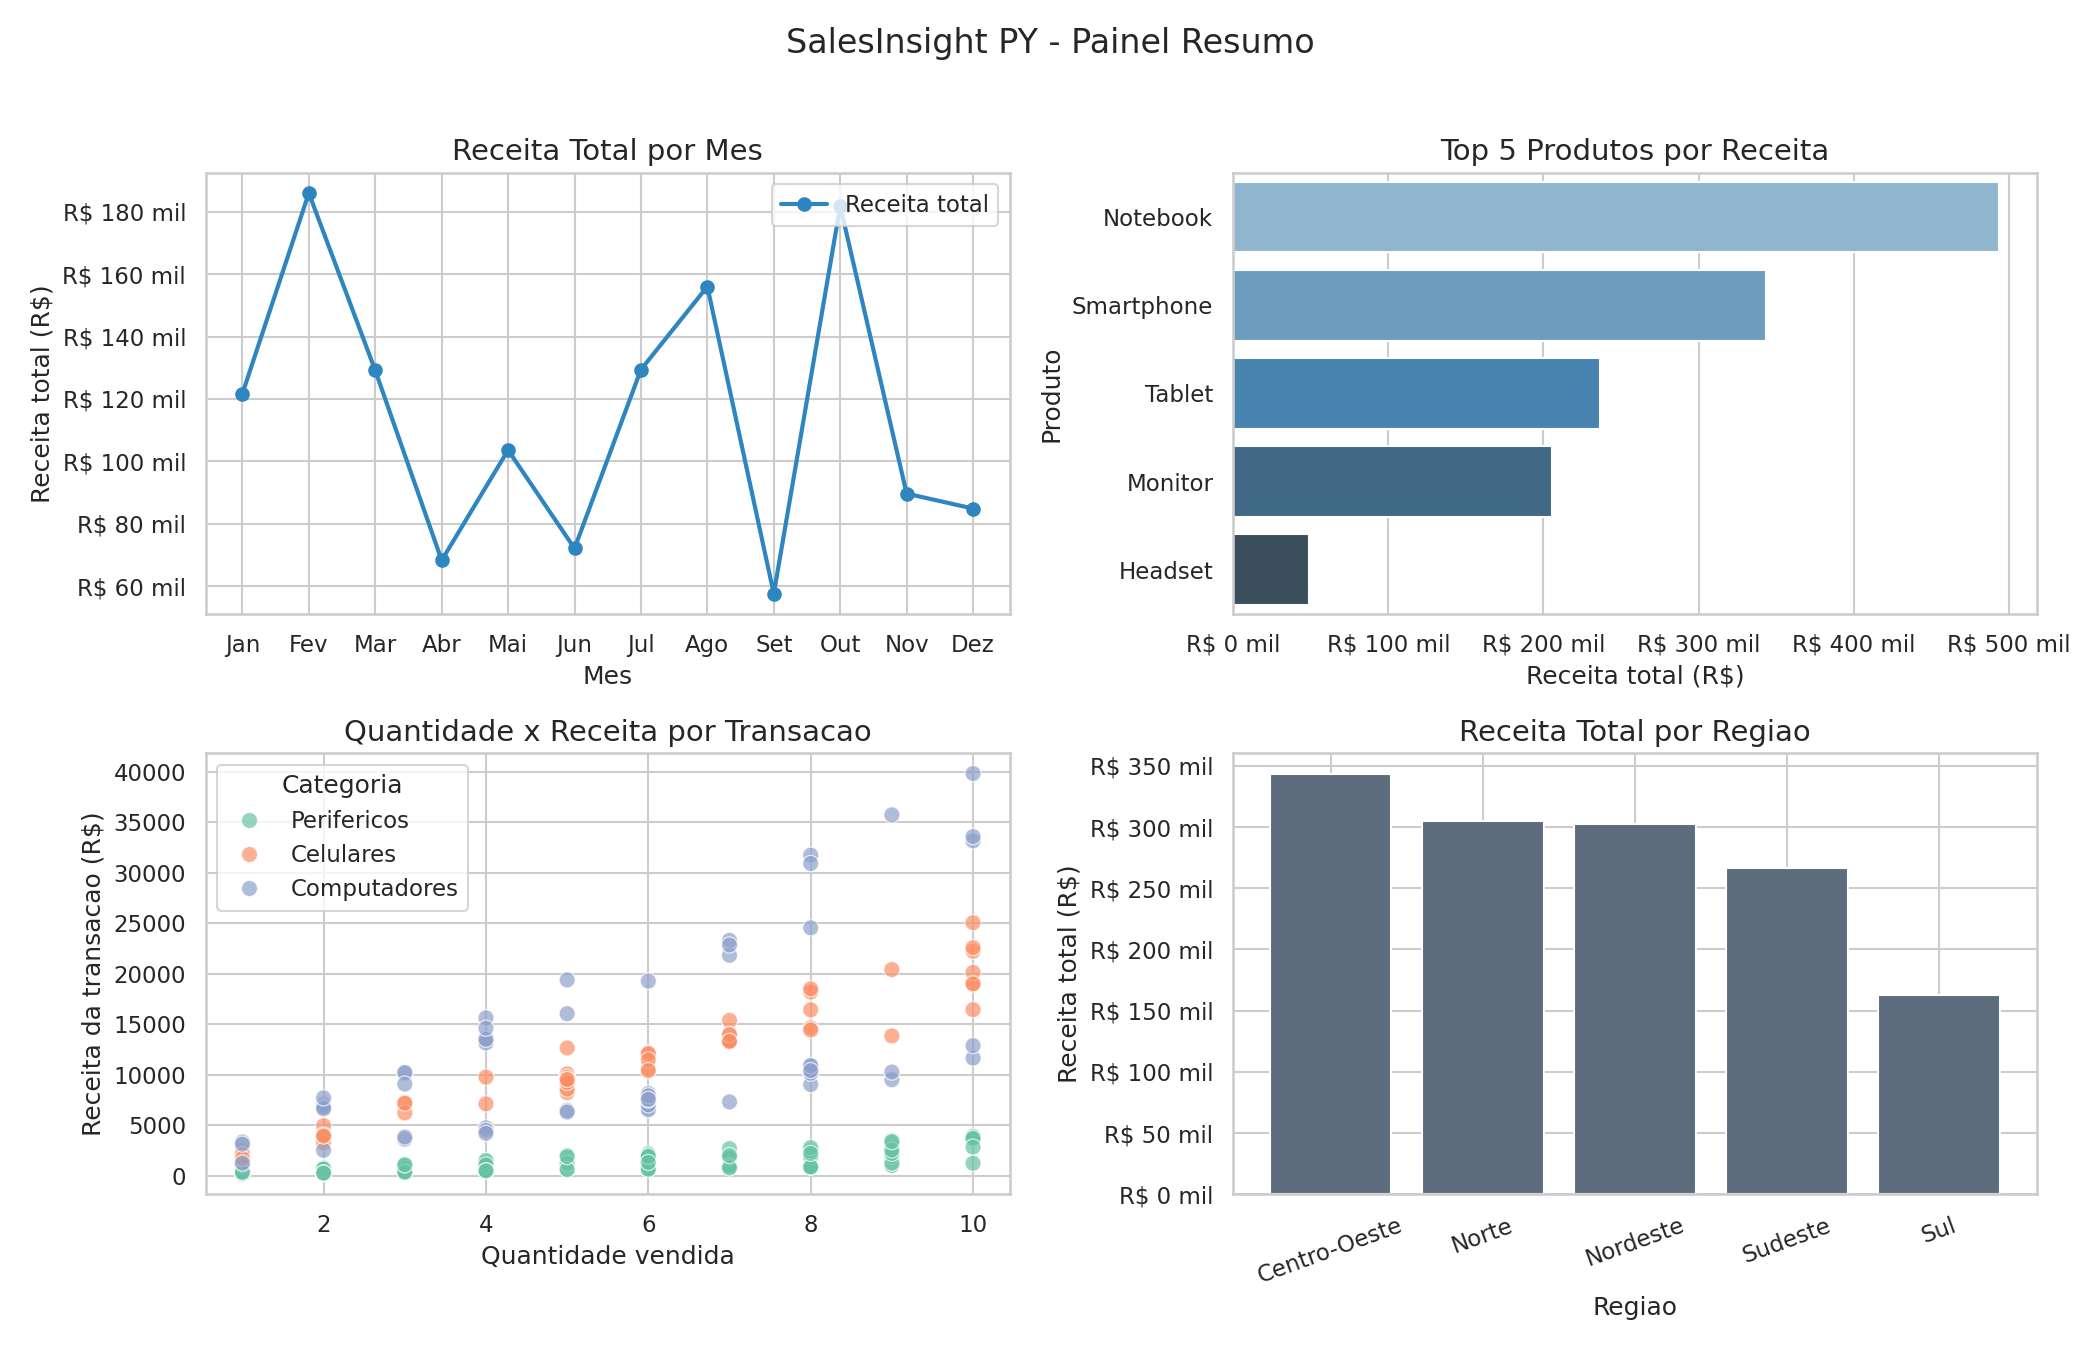

In [17]:
from IPython.display import Image, display
display(Image("outputs/graficos/painel_resumo.png"))